# 08. Mitigation and Policy Tests

This notebook tests pollutant-specific prevention, cleanup, and containment projects with fixed policies.

Note: Project prices, effectiveness, capacities, delays, and lifetimes are synthetic scenario assumptions.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from study_3_pollutant_dynamics.config import EnvironmentConfig
from study_3_pollutant_dynamics.environment import PollutantDynamicsEnvironment
from study_3_pollutant_dynamics.economic_parameters import (REGIONAL_ECONOMIC_PARAMETERS, REGIONAL_EMISSION_PROFILE_MULTIPLIERS,
                                                            STAGE_2_SCENARIOS)

from study_3_pollutant_dynamics.scenario_parameters import get_parameters
from study_3_pollutant_dynamics.damage_parameters import DAMAGE_SCENARIOS
from study_3_pollutant_dynamics.mitigation_parameters import (MITIGATION_PROJECTS, MITIGATION_POLICIES,
                                                              PROJECT_PURCHASE_FREQUENCY_YEARS, DEVELOPMENT_COST_PER_EDI_POINT)

from study_3_pollutant_dynamics.mitigation import (project_is_active, active_project_count, prevention_fraction, cleanup_capacity,
                                                   lead_mobile_fraction, purchase_costs)

from study_3_pollutant_dynamics.regional_economics import (calculate_annual_income, calculate_emission_activity_index)

from study_3_pollutant_dynamics.environmental_damage import (update_lagged_exposure, calculate_pollutant_damage_fractions,
                                                             combine_damage_fractions, apply_income_damage)

## What each investment does

Prevention reduces new annual emissions or loads. PM2.5 is modeled as annual exposure rather than a stored stock, so the model has no PM2.5 cleanup action. CO2 cleanup represents removal through negative emissions in the existing impulse-response model. Nitrate cleanup removes mass from the water stock. Lead cleanup removes soil mass. Lead containment lowers the mobile fraction but leaves total lead in the soil.

Projects start after their stated delay and remain active for a finite period. The fixed policies buy a complete project package every five years when its cost is affordable. Development spending is paid first, then the mitigation package. A missed package is retried in following years until purchased.

In [2]:
project_rows = []

for category, projects in MITIGATION_PROJECTS.items():
    for pollutant, settings in projects.items():
        row = {"investment_type": category, "pollutant": pollutant}
        for parameter_name, value in settings.items():
            row[parameter_name] = value
        project_rows.append(row)

project_table = pd.DataFrame(project_rows)
display(project_table.fillna("").round(4))

,investment_type,pollutant,cost,emissions_reduction_fraction,delay_years,persistence_years,capacity_fraction_reference_emissions,capacity_fraction_initial_stock,mobile_fraction_multiplier
0,prevention,PM2.5,15.0,0.25,1,5,,,
1,prevention,CO2,40.0,0.15,1,5,,,
2,prevention,Nitrate-N,15.0,0.2,1,5,,,
3,prevention,Lead,10.0,0.25,1,5,,,
4,cleanup,CO2,45.0,,3,10,0.005,,
5,cleanup,Nitrate-N,25.0,,2,5,,0.05,
6,cleanup,Lead,30.0,,3,10,,0.005,
7,containment,Lead,20.0,,2,10,,,0.5


## Fixed policy simulation

Each region follows the same named policy, but has its own currency balance and income. Development-focused policies attempt to increase EDI by one point per year at a synthetic cost of 25 currency units per point. EDI increases only if the region can pay. Environmental projects are purchased by the whole package, not partially. The policy run uses the reference damage coefficients, which remain assumptions.

In [3]:
def prepare_policy_year(config, policy_name, policy_projects, year, state):
    year_data = {
        "edi_activity_factors": [],
        "edi_income_factors": [],
        "development_gains": [],
        "development_costs": [],
        "mitigation_package_costs": [],
        "package_purchased": [],
        "gross_incomes": [],
    }

    emission_elasticity = STAGE_2_SCENARIOS["emission_edi_elasticity"]["reference"]
    income_elasticity = STAGE_2_SCENARIOS["income_edi_elasticity"]["reference"]
    package_cost = purchase_costs(policy_projects)

    for region_index, region_parameters in enumerate(REGIONAL_ECONOMIC_PARAMETERS):
        edi_value = state["development_indices"][region_index]
        initial_edi = region_parameters["initial_edi"]

        activity_factor = calculate_emission_activity_index(1.0, edi_value, initial_edi, emission_elasticity)
        income_factor = calculate_annual_income(1.0, 0.0, 0, edi_value, initial_edi, income_elasticity)

        year_data["edi_activity_factors"].append(activity_factor)
        year_data["edi_income_factors"].append(income_factor)

        growth_rate = region_parameters["annual_income_growth_rate"]
        gross_income = state["previous_net_income"][region_index] * (1 + growth_rate)
        gross_income *= income_factor / state["previous_edi_income_factor"][region_index]

        year_data["gross_incomes"].append(gross_income)

        development_gain = 1.0

        if policy_name == "no_development_no_investment":
            development_gain = 0.0

        if edi_value >= 100:
            development_gain = 0.0

        development_cost = development_gain * DEVELOPMENT_COST_PER_EDI_POINT

        if state["balances"][region_index] < development_cost:
            development_gain = 0.0
            development_cost = 0.0

            if policy_name != "no_development_no_investment":
                state["failed_development_attempts"] += 1

        state["balances"][region_index] -= development_cost
        state["cumulative_development_spending"][region_index] += development_cost

        year_data["development_gains"].append(development_gain)
        year_data["development_costs"].append(development_cost)

        bought_package = False
        mitigation_cost = 0.0

        if policy_projects and year >= state["next_package_year"][region_index]:
            if state["balances"][region_index] >= package_cost:
                mitigation_cost = package_cost

                state["balances"][region_index] -= mitigation_cost
                state["cumulative_mitigation_spending"][region_index] += mitigation_cost

                for category, pollutant in policy_projects:
                    project = {
                        "category": category,
                        "pollutant": pollutant,
                        "investment_year": year,
                    }

                    state["projects_by_region"][region_index].append(project)

                state["next_package_year"][region_index] = year + PROJECT_PURCHASE_FREQUENCY_YEARS
                bought_package = True

            else:
                state["missed_investment_attempts"] += 1

        year_data["mitigation_package_costs"].append(mitigation_cost)
        year_data["package_purchased"].append(bought_package)

    return year_data

In [ ]:
def update_policy_emissions(config, year, state, year_data):
    config.pm25["annual_emission_change_tons"] = []
    config.co2["annual_emissions_gtco2_year"] = []
    config.nitrate["annual_input_kg_n"] = []
    config.lead["annual_input_kg_pb"] = []

    mitigation_data = {
        "lead_mobile_fractions": [],
        "nitrate_cleanup_capacities": [],
        "lead_cleanup_capacities": [],
        "co2_removal_capacities": [],
        "prevention_fractions": {"PM2.5": [], "CO2": [], "Nitrate-N": [], "Lead": []},
    }

    for region_index in range(len(config.regions)):
        projects = state["projects_by_region"][region_index]
        activity_factor = year_data["edi_activity_factors"][region_index]

        prevention_values = {}

        for pollutant in mitigation_data["prevention_fractions"]:
            fraction = prevention_fraction(projects, year, pollutant)
            prevention_values[pollutant] = fraction
            mitigation_data["prevention_fractions"][pollutant].append(fraction)

        pm25_emissions = 5000.0 * REGIONAL_EMISSION_PROFILE_MULTIPLIERS["PM2.5"][region_index]
        pm25_emissions *= activity_factor * (1 - prevention_values["PM2.5"])

        config.pm25["annual_emission_change_tons"].append(pm25_emissions)

        reference_co2 = config.co2["reference_emissions_gtco2_year"][region_index]
        co2_gross_emissions = reference_co2 * activity_factor * (1 - prevention_values["CO2"])

        co2_removal = cleanup_capacity(projects, year, "CO2", reference_co2, 0.0)
        co2_removal = min(co2_gross_emissions, co2_removal)

        mitigation_data["co2_removal_capacities"].append(co2_removal)
        config.co2["annual_emissions_gtco2_year"].append(co2_gross_emissions - co2_removal)

        nitrate_input = state["reference_nitrate_inputs"][region_index]
        nitrate_input *= REGIONAL_EMISSION_PROFILE_MULTIPLIERS["Nitrate-N"][region_index]
        nitrate_input *= activity_factor * (1 - prevention_values["Nitrate-N"])

        config.nitrate["annual_input_kg_n"].append(nitrate_input)

        nitrate_capacity = cleanup_capacity(projects, year, "Nitrate-N", 0.0, state["initial_nitrate_stocks"][region_index])
        mitigation_data["nitrate_cleanup_capacities"].append(nitrate_capacity)

        lead_input = state["reference_lead_inputs"][region_index]
        lead_input *= REGIONAL_EMISSION_PROFILE_MULTIPLIERS["Lead"][region_index]
        lead_input *= activity_factor * (1 - prevention_values["Lead"])

        config.lead["annual_input_kg_pb"].append(lead_input)

        lead_capacity = cleanup_capacity(projects, year, "Lead", 0.0, state["initial_lead_stocks"][region_index])
        mitigation_data["lead_cleanup_capacities"].append(lead_capacity)

        mobile_fraction = lead_mobile_fraction(projects, year, state["base_mobile_fraction"])
        mitigation_data["lead_mobile_fractions"].append(mobile_fraction)

    config.lead["mobile_fraction"] = list(mitigation_data["lead_mobile_fractions"])

    return mitigation_data

In [ ]:
def apply_policy_cleanup(environment, config, info, state, mitigation_data, nitrate_stocks_before_step, lead_stocks_before_step):
    cleanup_data = {
        "nitrate_removed": [],
        "lead_removed": [],
        "post_cleanup_nitrate": [],
        "post_cleanup_lead": [],
        "post_cleanup_mobile_lead": [],
    }

    for region_index in range(len(config.regions)):
        nitrate_before = info["stocks"]["Nitrate-N"][region_index]
        nitrate_capacity = mitigation_data["nitrate_cleanup_capacities"][region_index]

        nitrate_removed_mass = min(nitrate_before, nitrate_capacity)
        nitrate_after_cleanup = nitrate_before - nitrate_removed_mass

        cleanup_data["nitrate_removed"].append(nitrate_removed_mass)
        cleanup_data["post_cleanup_nitrate"].append(nitrate_after_cleanup)

        lead_before = info["stocks"]["Lead"][region_index]
        lead_capacity = mitigation_data["lead_cleanup_capacities"][region_index]

        lead_removed_mass = min(lead_before, lead_capacity)
        lead_after_cleanup = lead_before - lead_removed_mass
        lead_mobile_after_cleanup = lead_after_cleanup * mitigation_data["lead_mobile_fractions"][region_index]

        cleanup_data["lead_removed"].append(lead_removed_mass)
        cleanup_data["post_cleanup_lead"].append(lead_after_cleanup)
        cleanup_data["post_cleanup_mobile_lead"].append(lead_mobile_after_cleanup)

        nitrate_flow = info["nitrate_flows"][region_index]

        nitrate_residual = abs(nitrate_stocks_before_step[region_index] + config.nitrate["annual_input_kg_n"][region_index] - nitrate_flow["outflow_kg_n"] - nitrate_flow["denitrified_kg_n"] - nitrate_removed_mass - nitrate_after_cleanup)

        lead_flow = info["lead_flows"][region_index]

        lead_residual = abs(lead_stocks_before_step[region_index] + config.lead["annual_input_kg_pb"][region_index] - lead_flow["exported_kg_pb"] - lead_removed_mass - lead_after_cleanup)

        state["maximum_nitrate_mass_residual"] = max(state["maximum_nitrate_mass_residual"], nitrate_residual)
        state["maximum_lead_mass_residual"] = max(state["maximum_lead_mass_residual"], lead_residual)

    environment.stocks["Nitrate-N"] = tuple(cleanup_data["post_cleanup_nitrate"])
    environment.mobile_stocks["Nitrate-N"] = tuple(cleanup_data["post_cleanup_nitrate"])

    environment.stocks["Lead"] = tuple(cleanup_data["post_cleanup_lead"])
    environment.mobile_stocks["Lead"] = tuple(cleanup_data["post_cleanup_mobile_lead"])

    return cleanup_data

In [ ]:
def calculate_policy_income(config, info, year, state, year_data, mitigation_data, cleanup_data):
    regional_income_rows = []
    reference_damage = DAMAGE_SCENARIOS["reference"]

    state["lagged_co2_ppm"] = update_lagged_exposure(state["lagged_co2_ppm"], info["stocks"]["CO2"], reference_damage["co2_delay_years"])

    for region_index, region_parameters in enumerate(REGIONAL_ECONOMIC_PARAMETERS):
        pm25_value = info["stocks"]["PM2.5"][region_index]
        pm25_reference = config.pm25["baseline_exposure_ug_m3"][region_index]

        nitrate_stock = cleanup_data["post_cleanup_nitrate"][region_index]
        nitrate_concentration = 1000 * nitrate_stock / config.nitrate["water_volume_m3"]

        lead_mobile_stock = cleanup_data["post_cleanup_mobile_lead"][region_index]
        lead_mobile_concentration = lead_mobile_stock / config.lead["soil_mass_kg"] * 1000000

        previous_lead_exposure = state["lagged_lead_mobile_mg_kg"][region_index]
        lagged_lead_exposure = update_lagged_exposure(previous_lead_exposure, lead_mobile_concentration, reference_damage["lead_delay_years"])

        state["lagged_lead_mobile_mg_kg"][region_index] = lagged_lead_exposure

        damage_fractions = calculate_pollutant_damage_fractions(pm25_value, pm25_reference, state["lagged_co2_ppm"], state["co2_reference"], nitrate_concentration, state["nitrate_reference"], lagged_lead_exposure, state["initial_lead_mobile_mg_kg"][region_index], reference_damage)

        total_damage = combine_damage_fractions(damage_fractions)
        gross_income = year_data["gross_incomes"][region_index]
        net_income = apply_income_damage(gross_income, total_damage)

        state["cumulative_income"][region_index] += net_income
        state["balances"][region_index] += net_income
        state["previous_net_income"][region_index] = net_income
        state["previous_edi_income_factor"][region_index] = year_data["edi_income_factors"][region_index]

        if year_data["development_gains"][region_index] > 0:
            state["development_indices"][region_index] += year_data["development_gains"][region_index]

        row = {
            "region": region_parameters["region"],
            "year": year,
            "EDI": state["development_indices"][region_index],
            "currency": state["balances"][region_index],
            "gross_income": gross_income,
            "net_income": net_income,
            "cumulative_net_income": state["cumulative_income"][region_index],
            "damage_fraction": total_damage,
            "development_cost": year_data["development_costs"][region_index],
            "mitigation_cost": year_data["mitigation_package_costs"][region_index],
            "package_purchased": year_data["package_purchased"][region_index],
            "prevention_PM2.5": mitigation_data["prevention_fractions"]["PM2.5"][region_index],
            "prevention_CO2": mitigation_data["prevention_fractions"]["CO2"][region_index],
            "prevention_Nitrate-N": mitigation_data["prevention_fractions"]["Nitrate-N"][region_index],
            "prevention_Lead": mitigation_data["prevention_fractions"]["Lead"][region_index],
            "Nitrate_cleanup_kg": cleanup_data["nitrate_removed"][region_index],
            "Lead_cleanup_kg": cleanup_data["lead_removed"][region_index],
            "Lead_mobile_kg": lead_mobile_stock,
            "CO2_removal_Gt_year": mitigation_data["co2_removal_capacities"][region_index],
        }

        regional_income_rows.append(row)

    return regional_income_rows

In [ ]:
def record_policy_trajectory(config, info, year, regional_income_rows, cleanup_data):
    region_count = len(config.regions)

    mean_nitrate = 0.0
    mean_lead = 0.0
    mean_lead_mobile = 0.0

    for region_index in range(region_count):
        nitrate_stock = cleanup_data["post_cleanup_nitrate"][region_index]
        lead_stock = cleanup_data["post_cleanup_lead"][region_index]
        lead_mobile_stock = cleanup_data["post_cleanup_mobile_lead"][region_index]

        mean_nitrate += 1000 * nitrate_stock / config.nitrate["water_volume_m3"]
        mean_lead += lead_stock
        mean_lead_mobile += lead_mobile_stock

    mean_nitrate /= region_count
    mean_lead /= region_count
    mean_lead_mobile /= region_count

    regional_income = pd.DataFrame(regional_income_rows)

    row = {
        "year": year,
        "mean_EDI": regional_income["EDI"].mean(),
        "mean_currency": regional_income["currency"].mean(),
        "mean_net_income": regional_income["net_income"].mean(),
        "mean_damage_fraction": regional_income["damage_fraction"].mean(),
        "mean_PM2.5_ug_m3": sum(info["stocks"]["PM2.5"]) / region_count,
        "CO2_ppm": info["stocks"]["CO2"],
        "mean_nitrate_mg_N_L": mean_nitrate,
        "mean_lead_total_kg": mean_lead,
        "mean_lead_mobile_kg": mean_lead_mobile,
        "mean_mitigation_spending": regional_income["mitigation_cost"].sum(),
    }

    return row

In [ ]:
def run_policy_episode(policy_name, starting_currency_multiplier, episode_steps=40):
    parameters = get_parameters(episode_steps=episode_steps)
    config = EnvironmentConfig(parameters)

    environment = PollutantDynamicsEnvironment(config)
    environment.reset(seed=0)

    policy_projects = MITIGATION_POLICIES[policy_name]

    state = {
        "development_indices": [],
        "balances": [],
        "previous_net_income": [],
        "previous_edi_income_factor": [],
        "cumulative_income": [],
        "cumulative_development_spending": [],
        "cumulative_mitigation_spending": [],
        "projects_by_region": [],
        "next_package_year": [],
        "initial_lead_mobile_mg_kg": [],
        "lagged_lead_mobile_mg_kg": [],
        "lagged_co2_ppm": config.co2["initial_concentration_ppm"],
        "co2_reference": config.co2["initial_concentration_ppm"],
        "nitrate_reference": config.nitrate["initial_concentration_mg_n_l"],
        "reference_nitrate_inputs": list(parameters["nitrate"]["annual_input_kg_n"]),
        "reference_lead_inputs": list(parameters["lead"]["annual_input_kg_pb"]),
        "initial_nitrate_stocks": list(config.nitrate["initial_stock_kg_n"]),
        "initial_lead_stocks": list(config.lead["initial_stock_kg_pb"]),
        "base_mobile_fraction": config.lead["mobile_fraction"],
        "missed_investment_attempts": 0,
        "failed_development_attempts": 0,
        "maximum_nitrate_mass_residual": 0.0,
        "maximum_lead_mass_residual": 0.0,
    }

    for region_index, region_parameters in enumerate(REGIONAL_ECONOMIC_PARAMETERS):
        starting_currency = region_parameters["initial_currency"] * starting_currency_multiplier

        state["development_indices"].append(region_parameters["initial_edi"])
        state["balances"].append(starting_currency)
        state["previous_net_income"].append(region_parameters["annual_income"])
        state["previous_edi_income_factor"].append(1.0)
        state["cumulative_income"].append(0.0)
        state["cumulative_development_spending"].append(0.0)
        state["cumulative_mitigation_spending"].append(0.0)
        state["projects_by_region"].append([])
        state["next_package_year"].append(1)

        initial_mobile = environment.mobile_stocks["Lead"][region_index]
        initial_mobile_concentration = initial_mobile / config.lead["soil_mass_kg"] * 1000000

        state["initial_lead_mobile_mg_kg"].append(initial_mobile_concentration)
        state["lagged_lead_mobile_mg_kg"].append(initial_mobile_concentration)

    regional_rows = []
    trajectory_rows = []

    for year in range(1, episode_steps + 1):
        year_data = prepare_policy_year(config, policy_name, policy_projects, year, state)

        mitigation_data = update_policy_emissions(config, year, state, year_data)

        nitrate_stocks_before_step = list(environment.stocks["Nitrate-N"])
        lead_stocks_before_step = list(environment.stocks["Lead"])

        observations, terminated, truncated, info = environment.step()

        cleanup_data = apply_policy_cleanup(environment, config, info, state, mitigation_data, nitrate_stocks_before_step,
                                            lead_stocks_before_step)

        regional_income_rows = calculate_policy_income(config, info, year, state, year_data, mitigation_data, cleanup_data)

        trajectory_row = record_policy_trajectory(config, info, year, regional_income_rows, cleanup_data)

        trajectory_rows.append(trajectory_row)
        regional_rows.extend(regional_income_rows)

        if terminated or truncated:
            break

    final_row = trajectory_rows[-1]

    summary = {
        "policy": policy_name,
        "starting_currency_multiplier": starting_currency_multiplier,
        "final_mean_EDI": final_row["mean_EDI"],
        "final_mean_currency": final_row["mean_currency"],
        "final_CO2_ppm": final_row["CO2_ppm"],
        "final_mean_PM2.5_ug_m3": final_row["mean_PM2.5_ug_m3"],
        "final_mean_nitrate_mg_N_L": final_row["mean_nitrate_mg_N_L"],
        "final_mean_lead_total_kg": final_row["mean_lead_total_kg"],
        "final_mean_lead_mobile_kg": final_row["mean_lead_mobile_kg"],
        "total_development_spending": sum(state["cumulative_development_spending"]),
        "total_mitigation_spending": sum(state["cumulative_mitigation_spending"]),
        "total_net_income": sum(state["cumulative_income"]),
        "missed_investment_attempts": state["missed_investment_attempts"],
        "failed_development_attempts": state["failed_development_attempts"],
        "total_nitrate_removed_kg": 0.0,
        "total_lead_removed_kg": 0.0,
        "total_CO2_removed_Gt": 0.0,
        "maximum_nitrate_mass_balance_residual_kg": state["maximum_nitrate_mass_residual"],
        "maximum_lead_mass_balance_residual_kg": state["maximum_lead_mass_residual"],
    }

    for row in regional_rows:
        summary["total_nitrate_removed_kg"] += row["Nitrate_cleanup_kg"]
        summary["total_lead_removed_kg"] += row["Lead_cleanup_kg"]
        summary["total_CO2_removed_Gt"] += row["CO2_removal_Gt_year"]

    trajectory = pd.DataFrame(trajectory_rows)
    regional_results = pd.DataFrame(regional_rows)

    return trajectory, regional_results, summary

In [4]:
policy_names = ("no_development_no_investment", "development_only", "prevention_focused", "cleanup_focused", "balanced")
currency_multipliers = (0.5, 1.0, 1.5)
summary_rows = []
trajectory_results = {}
regional_results = {}

for currency_multiplier in currency_multipliers:
    for policy_name in policy_names:
        trajectory, regions, summary = run_policy_episode(policy_name, currency_multiplier)
        summary_rows.append(summary)
        result_key = f"{policy_name}_{currency_multiplier}"
        trajectory_results[result_key] = trajectory
        regional_results[result_key] = regions

policy_summary = pd.DataFrame(summary_rows)

## Development and economic outcomes

This table shows final development and currency by policy and starting-balance level. Currency balances include starting resources, income after the assumed pollution damages, development spending, and project purchases.

In [5]:
economic_columns = ["policy", "starting_currency_multiplier", "final_mean_EDI", "final_mean_currency", "failed_development_attempts"]
economic_outcomes = policy_summary[economic_columns]
display(economic_outcomes.round(3))

,policy,starting_currency_multiplier,final_mean_EDI,final_mean_currency,failed_development_attempts
0,no_development_no_investment,0.5,65.00,2980.710,0
1,development_only,0.5,98.75,2017.438,0
2,prevention_focused,0.5,98.75,1970.646,0
3,cleanup_focused,0.5,95.25,1568.340,14
4,balanced,0.5,97.50,1294.180,5
5,no_development_no_investment,1.0,65.00,3293.210,0
6,development_only,1.0,98.75,2329.938,0
7,prevention_focused,1.0,98.75,2283.146,0
8,cleanup_focused,1.0,97.00,1811.432,7
9,balanced,1.0,98.75,1613.995,0


## Environmental outcomes

These endpoints show how the assumed project effects change each pollutant measure. PM2.5 is annual exposure; CO2 is the shared atmospheric concentration; nitrate-N is water concentration; lead reports both total and mobile soil mass.

In [6]:
environment_columns = ["policy", "starting_currency_multiplier", "final_CO2_ppm", "final_mean_PM2.5_ug_m3",
                       "final_mean_nitrate_mg_N_L", "final_mean_lead_total_kg", "final_mean_lead_mobile_kg"]
environmental_outcomes = policy_summary[environment_columns]
display(environmental_outcomes.round(4))

,policy,starting_currency_multiplier,final_CO2_ppm,final_mean_PM2.5_ug_m3,final_mean_nitrate_mg_N_L,final_mean_lead_total_kg,final_mean_lead_mobile_kg
0,no_development_no_investment,0.5,525.6200,8.6860,2.2575,16.2153,0.0063
1,development_only,0.5,529.6621,8.7365,3.2094,17.1226,0.0066
2,prevention_focused,0.5,526.7494,8.6931,2.5675,15.9208,0.0062
3,cleanup_focused,0.5,529.3868,8.7309,3.0010,13.1582,0.0051
4,balanced,0.5,526.9969,8.7048,2.6641,12.2598,0.0022
5,no_development_no_investment,1.0,525.6200,8.6860,2.2575,16.2153,0.0063
6,development_only,1.0,529.6621,8.7365,3.2094,17.1226,0.0066
7,prevention_focused,1.0,526.7494,8.6931,2.5675,15.9208,0.0062
8,cleanup_focused,1.0,529.4949,8.7339,3.0648,13.0371,0.0050
9,balanced,1.0,526.7312,8.7065,2.6988,11.7856,0.0015


## Spending and affordability

Mitigation spending is the cost of purchased project packages. Missed attempts record package purchase dates when the region did not have enough currency after development spending. Physical removals are reported separately from spending.

In [7]:
resource_columns = ["policy", "starting_currency_multiplier", "total_development_spending", "total_mitigation_spending",
                    "total_net_income", "missed_investment_attempts", "total_CO2_removed_Gt", "total_nitrate_removed_kg", "total_lead_removed_kg"]

resource_outcomes = policy_summary[resource_columns]
display(resource_outcomes.round(3))

,policy,starting_currency_multiplier,total_development_spending,total_mitigation_spending,total_net_income,missed_investment_attempts,total_CO2_removed_Gt,total_nitrate_removed_kg,total_lead_removed_kg
0,no_development_no_investment,0.5,0.0,0.0,10672.842,0,0.000,0.000000e+00,0.000
1,development_only,0.5,3375.0,0.0,10194.753,0,0.000,0.000000e+00,0.000
2,prevention_focused,0.5,3375.0,2560.0,12567.583,0,0.000,0.000000e+00,0.000
3,cleanup_focused,0.5,3025.0,2900.0,10948.359,15,1.541,5.089159e+08,15.699
4,balanced,0.5,3250.0,5800.0,12976.720,18,1.477,4.979321e+08,15.333
5,no_development_no_investment,1.0,0.0,0.0,10672.842,0,0.000,0.000000e+00,0.000
6,development_only,1.0,3375.0,0.0,10194.753,0,0.000,0.000000e+00,0.000
7,prevention_focused,1.0,3375.0,2560.0,12567.583,0,0.000,0.000000e+00,0.000
8,cleanup_focused,1.0,3200.0,3000.0,10945.727,10,1.599,5.272222e+08,16.310
9,balanced,1.0,3375.0,6200.0,13530.980,5,1.639,5.455285e+08,16.738


At the proposed starting balances (multiplier 1.0), the development-only and balanced policies both end at mean EDI 98.75. The balanced policy spends 6,200 currency units on mitigation; it ends with less currency than development-only, while its final PM2.5, CO2, nitrate-N, and lead values are lower under these assumptions.

Starting with half the proposed currency, the balanced policy misses 18 project-package purchases and five development attempts across the four regions. Its final mean EDI is 97.5, compared with 98.75 at the standard and 1.5x starting balances. Cleanup-heavy policies also miss more development attempts at low cash. This shows the assumed timing and package costs can make starting liquidity affect both project uptake and development.

The reference lead cleanup capacity is 0.5% of initial parcel stock per active project per year, chosen to be near the scale of the assumed annual lead input. Nitrate cleanup is 5% of initial water stock per project per year.

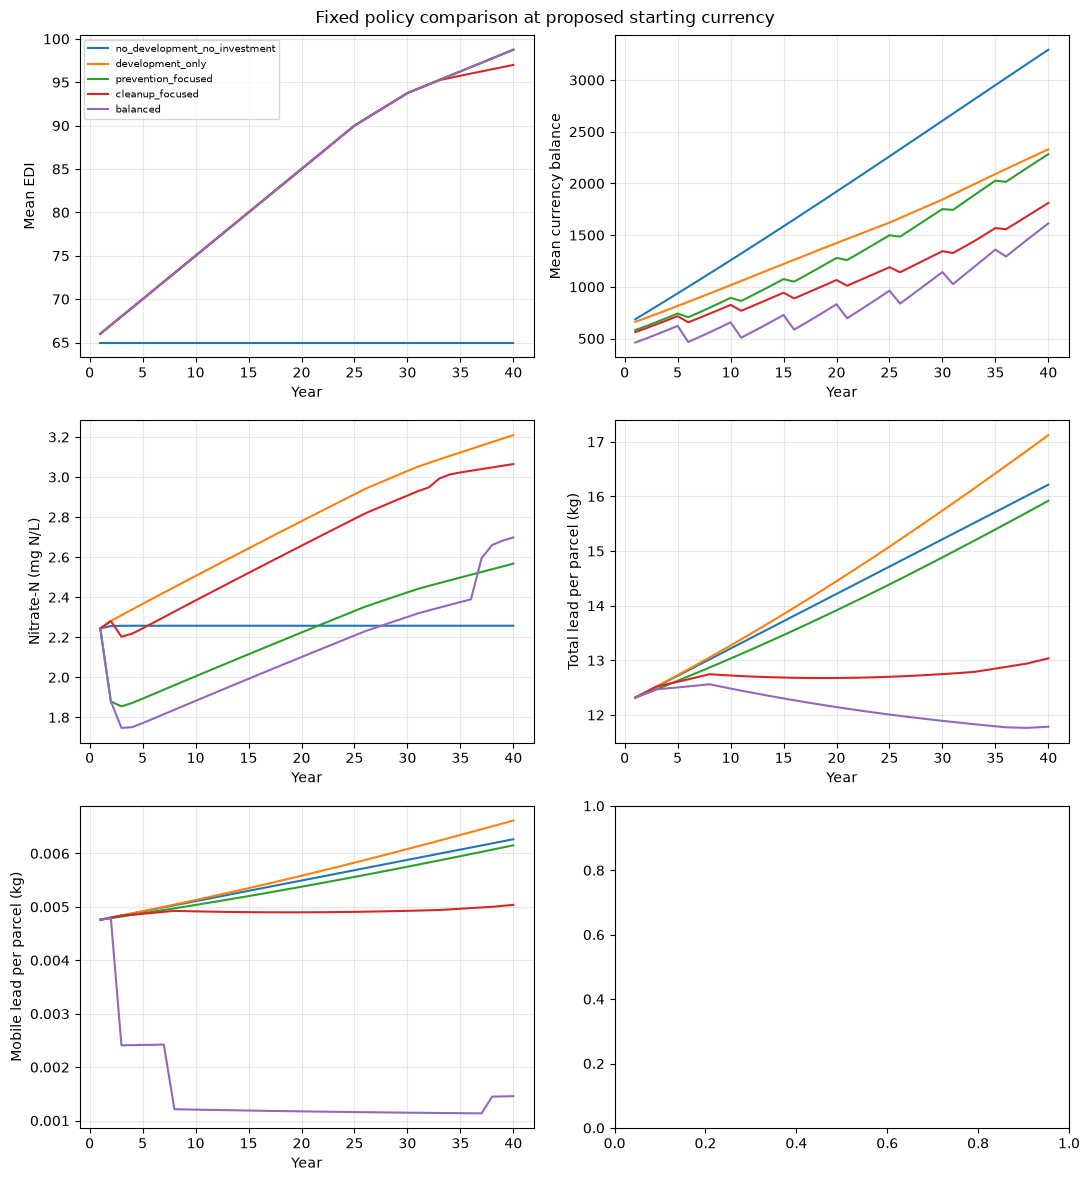

In [8]:
plot_metrics = (("mean_EDI", "Mean EDI"), ("mean_currency", "Mean currency balance"), ("mean_nitrate_mg_N_L", "Nitrate-N (mg N/L)"),
                ("mean_lead_total_kg", "Total lead per parcel (kg)"), ("mean_lead_mobile_kg", "Mobile lead per parcel (kg)"))
figure, axes = plt.subplots(3, 2, figsize=(11, 12))

for axis, metric in zip(axes.flat, plot_metrics):
    metric_name, axis_label = metric
    for policy_name in policy_names:
        result_key = f"{policy_name}_1.0"
        trajectory = trajectory_results[result_key]
        axis.plot(trajectory["year"], trajectory[metric_name], label=policy_name)
    axis.set_xlabel("Year")
    axis.set_ylabel(axis_label)
    axis.grid(alpha=0.3)

axes[0, 0].legend(fontsize=7)
figure.suptitle("Fixed policy comparison at proposed starting currency")
plt.tight_layout()
plt.show()

## Checks and limits

These checks confirm project timing, nonnegative budget balances, and mass accounting when nitrate or lead is physically removed. Lead containment changes mobility but must not remove total lead.

In [9]:
check_rows = []

sample_project = {"category": "prevention", "pollutant": "PM2.5", "investment_year": 1}

check_rows.append({"check": "Prevention project is inactive before its delay", "passed": not project_is_active(sample_project, 1)})
check_rows.append({"check": "Prevention project activates after one year", "passed": project_is_active(sample_project, 2)})
check_rows.append({"check": "Prevention project expires after its persistence", "passed": not project_is_active(sample_project, 7)})
check_rows.append({"check": "Active PM2.5 prevention reduces new emissions", "passed": prevention_fraction([sample_project], 2, "PM2.5") > 0})

containment_project = {"category": "containment", "pollutant": "Lead", "investment_year": 1}

base_lead_mobile_fraction = get_parameters()["lead"]["mobile_fraction"]
contained_mobile_fraction = lead_mobile_fraction([containment_project], 3, base_lead_mobile_fraction)

check_rows.append({"check": "Lead containment lowers the mobile fraction after its delay", "passed": 0 < contained_mobile_fraction < base_lead_mobile_fraction})

,check,passed
0,Prevention project is inactive before its delay,True
1,Prevention project activates after one year,True
2,Prevention project expires after its persistence,True
3,Active PM2.5 prevention reduces new emissions,True
4,Lead containment lowers the mobile fraction af...,True
5,no_development_no_investment budgets remain no...,True
6,development_only budgets remain nonnegative,True
7,prevention_focused budgets remain nonnegative,True
8,cleanup_focused budgets remain nonnegative,True
9,balanced budgets remain nonnegative,True


Passed 13 of 13 checks.


In [ ]:
for policy_name in policy_names:
    trajectory = trajectory_results[f"{policy_name}_1.0"]
    regions = regional_results[f"{policy_name}_1.0"]

    no_negative_currency = (regions["currency"] >= 0).all()

    check_rows.append({"check": f"{policy_name} budgets remain nonnegative", "passed": no_negative_currency})

In [ ]:
policy_filter = policy_summary["policy"] == "balanced"
currency_filter = policy_summary["starting_currency_multiplier"] == 1.0

balanced_summary = policy_summary[policy_filter & currency_filter].iloc[0]

lead_mass_residual = balanced_summary["maximum_lead_mass_balance_residual_kg"]
nitrate_mass_residual = balanced_summary["maximum_nitrate_mass_balance_residual_kg"]

check_rows.append({"check": "Nitrate removal is explicitly included in mass accounting", "passed": nitrate_mass_residual < 1e-5})
check_rows.append({"check": "Lead removal is explicitly included in mass accounting", "passed": lead_mass_residual < 1e-10})

mitigation_spending = balanced_summary["total_mitigation_spending"]

check_rows.append({"check": "Balanced policy records mitigation expenditure", "passed": mitigation_spending > 0})

checks_table = pd.DataFrame(check_rows)
display(checks_table)

In [ ]:
passed_count = checks_table["passed"].sum()
total_checks = len(checks_table)

print(f"Passed {passed_count} of {total_checks} checks.")